In [1]:
import langgraph

In [2]:
from langchain.agents import create_agent

In [3]:
#

# LangGraph: Nodes, Edges aur State

## 1. Nodes (नोड्स)

Node ek function hota hai jo koi specific task perform karta hai.

Examples:

* LLM ko call karna
* Database se data retrieve karna
* Tool execute karna
* Answer validate karna

```python
def chatbot(state):
    return {
        "answer": f"Aapne poochha: {state['question']}"
    }
```

Yahan `chatbot` ek Node hai. Yeh State se question leta hai aur answer return karta hai.

## 2. Edges (एजेस)

Edge decide karta hai ki ek Node ke baad kaunsa Node execute hoga.

### A. Normal Edge

Ek Node se doosre Node par directly jaana.

```python
builder.add_edge("node_a", "node_b")
```

### B. Conditional Edge

Condition ke basis par decide karna ki next kaunsa Node execute hoga.

```python
builder.add_conditional_edges(
    "check",
    route_function
)
```

### C. START aur END

* `START`: Graph ki execution yahan se shuru hoti hai.
* `END`: Graph ki execution yahan khatam hoti hai.

## 3. State (स्टेट)

State ek shared data structure hai jisme graph ke execution ke dauran data store aur update hota hai.

Example:

```python
from typing import TypedDict

class State(TypedDict):
    question: str
    answer: str
```

* `question`: User ka question.
* `answer`: AI ka response.
* Nodes State se data read karte hain aur updates return karte hain.
* LangGraph returned updates ko State mein merge karta hai.

## 4. Complete Example

```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# Define State
class State(TypedDict):
    question: str
    answer: str

# Define Node
def chatbot(state: State):
    return {
        "answer": f"Aapne poochha: {state['question']}"
    }

# Create Graph
builder = StateGraph(State)

# Add Node
builder.add_node("chatbot", chatbot)

# Add Edges
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

# Compile Graph
graph = builder.compile()

# Execute Graph
result = graph.invoke({
    "question": "LangGraph kya hai?",
    "answer": ""
})

print(result["answer"])
```

Output:

```text
Aapne poochha: LangGraph kya hai?
```

## 5. Quick Revision

* Node = Kya kaam karna hai.
* Edge = Agla kaam kahan hoga.
* State = Data kahan store aur update hoga.
* START = Graph ki shuruaat.
* END = Graph ka ant.

Example: Ek chatbot mein Node LLM ko call karta hai, Edge decide karta hai ki next step kya hoga, aur State user ka question aur AI ka answer store karti hai.



In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')


In [6]:
from langchain.chat_models import init_chat_model

In [7]:
from langchain.chat_models import init_chat_model
model=init_chat_model(model='openai/gpt-oss-20b',model_provider='groq')

In [8]:
model.invoke('hello')

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hello". They are greeting. We respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 72, 'total_tokens': 105, 'completion_time': 0.036226236, 'completion_tokens_details': {'reasoning_tokens': 15}, 'prompt_time': 0.003375285, 'prompt_tokens_details': None, 'queue_time': 0.382885282, 'total_time': 0.039601521}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12a98-b145-7270-96cd-10442def466c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 33, 'total_tokens': 105, 'output_token_details': {'reasoning': 15}})

In [9]:

from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

from langgraph.graph.message import add_messages

class state(TypedDict):
    messages:Annotated[list, add_messages] # Naye messages ko existing list mein append karta hai (overwrite nahi karta)

graph_builder= StateGraph(state)

TypedDict  →  Form ka template (kaunse fields honge)


Annotated  →  Form ke fields pe instructions likhna
              (e.g., "yahan sirf number likhein")


add_messages → Wo instruction jo bataye "purana data rakhte hue naya add karo"


In [10]:
def chatbot(state:state):
    return {'messages':[model.invoke(state['messages'])]}

In [11]:
graph_builder.add_node('llmchatbot', chatbot)# ADD edge
graph_builder.add_edge(START, 'llmchatbot')
graph_builder.add_edge('llmchatbot', END)

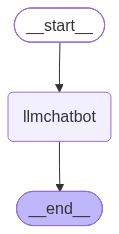

In [12]:
graph_builder.compile()

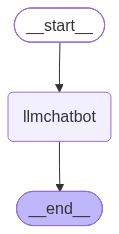

In [13]:

from IPython.display import Image,display

try:
    graph = graph_builder.compile()
# Phir display karo
    display(Image(graph.get_graph().draw_mermaid_png()))
except:
    pass

In [14]:
responce=graph.invoke({'messages':'mohit payasi who is data science trianer'})
responce['messages'][-1].content

'**Mohit Payasi – Data‑Science Trainer**\n\n| Category | Details |\n|----------|---------|\n| **Professional identity** | Data‑science trainer, mentor and content creator based in India. |\n| **Primary focus** | Teaching Python, machine‑learning fundamentals, deep‑learning frameworks, data‑analysis workflows, and industry‑ready project pipelines. |\n| **Teaching format** | • **Live workshops & bootcamps** (online & in‑person)<br>• **Self‑paced video courses** (YouTube, Udemy‑style platforms)<br>• **Hands‑on coding labs** and real‑world case studies |\n| **Typical curriculum** | 1. Python for data science (NumPy, Pandas, Matplotlib)<br>2. Exploratory data analysis & visualization<br>3. Machine‑learning algorithms (scikit‑learn, XGBoost, LightGBM)<br>4. Deep learning (TensorFlow/Keras, PyTorch)<br>5. NLP & computer‑vision basics<br>6. Model deployment & MLOps fundamentals |\n| **Target audience** | • Beginners with no coding experience<br>• Engineers looking to transition into data scien

In [15]:
for i in graph.stream({'messages':'data science trianer'}):
    print(i)

{'llmchatbot': {'messages': [AIMessage(content="## 🌟 “Data Science Trainer” – What It Means & How to Become One\n\nA **Data Science Trainer** (sometimes called a *Data Science Educator* or *Instructor*) is a professional who teaches the concepts, techniques, and tools that make up the data‑science ecosystem. They work in universities, corporate learning & development, bootcamps, online platforms, or as independent consultants.\n\nBelow is a quick‑reference guide that covers:\n\n| Section | What you’ll learn |\n|---------|-------------------|\n| **1️⃣ Role & Responsibilities** | Day‑to‑day tasks, skill mix, and the impact you can create |\n| **2️⃣ Core Competencies** | Technical, pedagogical, and soft‑skill requirements |\n| **3️⃣ Pathways to the Job** | Education, experience, and certifications |\n| **4️⃣ Sample Curriculum** | A starter syllabus you can adapt for in‑person or online courses |\n| **5️⃣ Resources & Tools** | Books, MOOCs, communities, and teaching aids |\n| **6️⃣ Buildin

In [16]:
for i in graph.stream({'messages':'data science trianer'}):
    for value in i.values():
        print(value['messages'][-1].content)

Sure! Whether you’re looking to **learn data science yourself** or to **train a team**, there are plenty of high‑quality resources—from free MOOCs to intensive bootcamps, books, and community‑driven learning. Below is a curated list of the most popular and effective options as of 2026.

---

## 1. Structured Learning Paths

| Platform | Typical Course Structure | Cost | Highlights |
|----------|--------------------------|------|------------|
| **Coursera** | Specializations, MasterTrack certificates | Free audit / $50–$400 for certificates | University‑backed, hands‑on projects, peer reviews |
| **edX** | MicroMasters, Professional Certificate | Free audit / $200–$600 for certificates | Deep dives in specific topics (e.g., AI, Big Data) |
| **Udacity** | Nanodegree programs | $399–$999 per month | Project‑based, mentorship, job‑prep |
| **DataCamp** | Skill tracks & courses | $25–$49/month | Interactive coding in the browser, instant feedback |
| **Kaggle Learn** | Micro‑courses | Free

In [17]:
# build react

# chat bot with tool

In [18]:
import os
from dotenv import load_dotenv
load_dotenv()  # .env file load karo
os.environ['TAVILY_API_KEY'] = os.getenv('TAVILY_API_KEY')

In [31]:

from langchain_tavily  import TavilySearch

In [20]:
tool= TavilySearch(max_results=7)

In [21]:
def multiply(a:int,b:int):
    """ a will be integer, b b will bw integer, 
    and you have to multiply both number and return as integer
    Args:
        a(int): first int
        b(int); second int

    Returns:
        int: output int    
    """
    




In [22]:
tool=[tool, multiply]
model_with_tool=model.bind_tools(tool)

In [ ]:
from langgraph.graph import StateGraph,START,END

from langgraph.prebuilt import ToolNode

from langgraph.prebuilt import tools_condition
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)

builder.add_edge('tools',END)
graph=builder.compile()


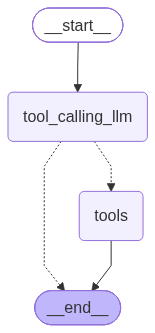

In [28]:
def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)

builder.add_edge('tools',END)
builder.compile()

In [32]:
graph.invoke({'messages':'what is the recent news of ai and find 5 multiply 6 '})

{'messages': [HumanMessage(content='what is the recent news of ai and find 5 multiply 6 ', additional_kwargs={}, response_metadata={}, id='bde4009b-72b3-4d8c-84ab-60f17d7fce75'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is the recent news of ai and find 5 multiply 6". Two tasks: 1) recent news of AI. Need to search. 2) compute 5 * 6. That is 30. We can use the multiply function. For news, use tavily_search with query "recent AI news 2026 October". Provide results.', 'tool_calls': [{'id': 'fc_9636a9e3-1c73-4cbc-b8d0-acd6f1010ec9', 'function': {'arguments': '{"query":"recent AI news 2026 October","search_depth":"advanced","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 389, 'total_tokens': 508, 'completion_time': 0.119844918, 'completion_tokens_details': {'reasoning_tokens': 79}, 'prompt_time': 0.02337995, 'prompt_tokens_details': None, 'queue_time

In [33]:
for i in graph.stream({'messages':'what is the recent news of ai and find 5 multiply 6 '}):
    for value in i.values():
        print(value['messages'][-1].content)


{'error': ValueError('Error 401: Unauthorized: missing or invalid API key.')}
I’m sorry, but I couldn’t retrieve live search results because the search tool is currently unable to access the web (the API key is missing or invalid).  

I can still share a quick summary of some of the most talked‑about AI developments that have been reported in the news up to early October 2026, and I’ll answer the arithmetic question you asked.

---

## Recent AI News (early October 2026)

| Date (approx.) | Topic | Key Takeaway |
|----------------|-------|--------------|
| **Oct 6 2026** | *OpenAI launches GPT‑5.5* | A new model with multimodal capabilities (text, image, audio) and a 10‑fold reduction in inference latency. OpenAI claims it can run on consumer GPUs in real time. |
| **Oct 4 2026** | *AI‑driven climate modeling* | A consortium of universities released a deep‑learning framework that predicts regional climate shifts with 95 % accuracy for the next 30 years, aiding policy decisions. |
| **

In [ ]:
# ReAct = Reasoning + Acting

# Yeh ek AI Agent pattern hai jahan LLM pehle sochta hai,
#  phir action leta hai, phir result dekhta hai — aur yeh loop tab tak chalta hai jab tak final
#   answer na mile.

In [ ]:
# Question aaya
#     ↓
# 🧠 THOUGHT  → "Mujhe pehle weather API call karni chahiye"
#     ↓
# ⚡ ACTION   → weather_tool("Delhi")
#     ↓
# 👁️ OBSERVATION → "Delhi: 35°C, Sunny"
#     ↓
# 🧠 THOUGHT  → "Ab main answer de sakta hoon"
#     ↓
# ✅ FINAL ANSWER → "Delhi mein aaj 35°C hai aur dhoop hai"

#---------------------------------------------------------------------------------------------------
# feature	               Normal LLM	                  ReAct Agent
# Memory	          ❌ Sirf training data	            ✅ Tools se live data
# Tools use	          ❌ Nahi kar sakta	                ✅ Haan kar sakta hai
# Multi-step	      ❌ Ek shot answer	                ✅ Step by step sochta hai
# Self-correction	  ❌ Nahi	                        ✅ Observation se seekhta hai

In [38]:
from langgraph.graph import StateGraph,START,END

from langgraph.prebuilt import ToolNode

from langgraph.prebuilt import tools_condition
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)
builder.add_edge('tools','tool_calling_llm')
builder.add_edge('tools',END)
graph1=builder.compile()

In [40]:
for i in graph1.stream({'messages':'what is the recent news of ai and find 5 multiply 6  what is weather of london'}):
    for value in i.values():
        print(value['messages'][-1].content)


{'error': ValueError('Error 401: Unauthorized: missing or invalid API key.')}
I’m sorry, but I don’t have the ability to pull in real‑time data (such as the latest news or current weather). I can give you a quick summary of the most recent AI developments that were publicly reported up to my last update (June 2024), and I can tell you how to find the current weather for London, but I can’t provide the actual live figures for today.

---

### 1. Recent AI news (up to mid‑2024)

| Date | Highlight | Key Takeaway |
|------|-----------|--------------|
| **May 2024** | OpenAI released GPT‑4.5 Turbo, a more efficient version of GPT‑4, with better cost‑efficiency and lower latency for large‑scale deployments. | AI developers can now run GPT‑4‑level models at a fraction of the cost, accelerating adoption in enterprise settings. |
| **April 2024** | Google announced “Pathways Language Model (PaLM‑2)” with improved reasoning and multimodal capabilities. | PaLM‑2 can understand images and text t

In [ ]:
# memory implementation of AI agent with langgraph
# LangGraph mein memory ka kaam karta hai Checkpointer — jo har step ka State save karta rehta hai.

In [45]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
from langgraph.prebuilt import ToolNode

from langgraph.prebuilt import tools_condition
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)
builder.add_edge('tools','tool_calling_llm')
builder.add_edge('tools',END)

graph2=builder.compile(checkpointer=memory)

In [48]:
config= {'configurable':{'thread_id':'mohit_chat_1'}}

graph2.invoke({'messages':'hey my name is mohit'},config=config)

{'messages': [HumanMessage(content='hey my name is mohit', additional_kwargs={}, response_metadata={}, id='db72618b-7cae-4275-a221-7e4809bad362'),
  AIMessage(content='Hello Mohit! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hey my name is mohit". Likely wants a greeting. Just respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 380, 'total_tokens': 421, 'completion_time': 0.042781233, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.252579416, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.307691845, 'total_time': 0.295360649}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e594c51153', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ad7-2bfe-7c81-8fc8-443090a2fd12-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 380, 'output_tokens': 41, 'total_tokens': 421,

In [50]:
graph2.invoke({'messages':'tell me my name'},config=config)

{'messages': [HumanMessage(content='hey my name is mohit', additional_kwargs={}, response_metadata={}, id='db72618b-7cae-4275-a221-7e4809bad362'),
  AIMessage(content='Hello Mohit! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hey my name is mohit". Likely wants a greeting. Just respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 380, 'total_tokens': 421, 'completion_time': 0.042781233, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.252579416, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.307691845, 'total_time': 0.295360649}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e594c51153', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ad7-2bfe-7c81-8fc8-443090a2fd12-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 380, 'output_tokens': 41, 'total_tokens': 421,

In [54]:
for i in graph2.stream({'messages':'AI is dengor my name is mohit and find 5 multiply 6  what is weather of london'},config=config):
    for value in i.values():
        print(value['messages'][-1].content)

Sure thing!  

- **5 × 6 = 30**  

- **Weather in London**: I don’t have real‑time weather data access right now, so I can’t give you the current forecast. Check a reliable weather site (e.g., the Met Office, BBC Weather, or a weather app) for the latest conditions.


In [55]:
for i in graph2.stream({'messages':'AI is dengor, what is my name and find 5 multiply 6  what is weather of london'},config=config):
    for value in i.values():
        print(value['messages'][-1].content)

**AI is dengor**  

- Your name: **Mohit**  
- 5 × 6 = **30**  

**Weather in London:** I don’t have real‑time weather data right now, so I can’t give you the current forecast. Check a reliable weather site (e.g., the Met Office, BBC Weather, or a weather app) for the latest conditions.


In [56]:
# streaming



In [57]:
from langgraph.checkpoint.memory import MemorySaver
memory= MemorySaver()

def superbot(state:State):
    return {'messages':[model_with_tool.invoke(state['messages'])]}

In [ ]:
supe

<function __main__.superbot(state: __main__.State)>